# Model Eğitimi (adım adım)

Bu notebook, aday puanlama modelinin nasıl eğitildiğini adım adım gösterir.

- Her aday 5 özellikle tanımlanır: **eğitim, tecrübe, teknik beceri, iletişim, iş istikrarı**.
- 4 pozisyon × 4 tecrübe seviyesi = **16 Random Forest modeli** vardır.
- Burada önce tek bir modeli (**Yazılım Geliştirici · Yeni Mezun**) baştan eğitiyoruz, sonra 16 modelin sonuçlarına bakıyoruz.

Notebook, kayıtlı modelleri **değiştirmez**. Modelleri yeniden eğitmek için `ml` klasöründe `py train_candidates.py` komutu kullanılır.

In [1]:
import json

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from candidate_data import make_candidates
from candidate_model import FEATURES, LEVELS, POSITIONS, level_weights

LABELS = {"education_level": "Eğitim", "years_experience": "Tecrübe", "technical_skill": "Teknik beceri",
          "communication_skill": "İletişim", "job_stability": "İş istikrarı"}

## 1. Kriter ağırlıkları

Her pozisyon özelliklere farklı önem verir. Örneğin yazılımcıda teknik beceri, satışta iletişim öne çıkar.

In [2]:
pd.DataFrame({p["name"]: p["weights"] for p in POSITIONS.values()}).rename(index=LABELS).T

,Eğitim,Tecrübe,Teknik beceri,İletişim,İş istikrarı
Genel Pozisyon,0.15,0.2,0.30,0.20,0.15
Yazılım Geliştirici,0.10,0.2,0.45,0.10,0.15
Satış / Müşteri İlişkileri,0.05,0.2,0.10,0.45,0.20
Proje Yöneticisi,0.10,0.3,0.15,0.30,0.15


Tecrübe seviyesi bu ağırlıkları tekrar değiştirir. Stajyerde iş istikrarı hiç sayılmaz, kıdemlide tecrübe daha önemlidir.
Aşağıda **Yazılım Geliştirici** için 4 seviyenin ağırlıkları var (Model Raporu sayfasındaki tablo ile aynı).

In [3]:
pd.DataFrame({LEVELS[l]["name"]: level_weights("software", l) for l in LEVELS}).rename(index=LABELS).T

,Eğitim,Tecrübe,Teknik beceri,İletişim,İş istikrarı
Stajyer,0.2010,0.0804,0.5879,0.1307,0.0000
Yeni Mezun (Junior),0.1608,0.1407,0.5427,0.1106,0.0452
Deneyimli (Orta Seviye),0.1000,0.2000,0.4500,0.1000,0.1500
Kıdemli (Senior),0.0474,0.2275,0.4265,0.1137,0.1848


## 2. Eğitim verisini oluşturma

Etiketli gerçek işe alım verisi olmadığı için sentetik (yapay) adaylar üretiyoruz.
Ağırlıklara göre en iyi %35'lik kısım **kısa listeye alındı** (1), diğerleri **elendi** (0) olarak işaretleniyor.
Model bu kuralı bilmiyor, sadece sayılara bakarak öğrenmek zorunda.

In [4]:
POSITION, LEVEL = "software", "junior"
SEED = 48  # same seed as train_candidates.py, so the results match the Model Report page

weights = level_weights(POSITION, LEVEL)
data = make_candidates(weights, LEVELS[LEVEL], SEED)
print(f"{len(data)} aday üretildi, kısa listeye alınan oranı: %{data['shortlisted'].mean() * 100:.0f}")
data.head()

2000 aday üretildi, kısa listeye alınan oranı: %35


,education_level,years_experience,technical_skill,communication_skill,job_stability,shortlisted
0,1,1.0,67.0,83.0,1.0,0
1,1,1.0,53.0,55.0,1.0,0
2,1,1.5,93.0,75.0,0.5,1
3,1,1.5,61.0,74.0,1.5,1
4,1,1.5,76.0,73.0,1.5,1


## 3. Eğitim ve test verisine ayırma

Adayların %80'i ile model eğitilir, kalan %20'si ile test edilir. Model test adaylarını eğitimde hiç görmez.

In [5]:
X, y = data[FEATURES], data["shortlisted"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Eğitim:", len(X_train), "aday  ·  Test:", len(X_test), "aday")

Eğitim: 1600 aday  ·  Test: 400 aday


## 4. Random Forest modelini eğitme

Random Forest, 100 küçük karar ağacının oylamasıyla karar verir.

In [6]:
rf = RandomForestClassifier(n_estimators=100, max_depth=9, min_samples_leaf=3, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict(X_test)

print(f"Doğruluk  (Accuracy) : %{accuracy_score(y_test, pred) * 100:.1f}")
print(f"Kesinlik  (Precision): %{precision_score(y_test, pred) * 100:.1f}")
print(f"Duyarlılık (Recall)  : %{recall_score(y_test, pred) * 100:.1f}")
print(f"F1 puanı             : {f1_score(y_test, pred):.3f}")

Doğruluk  (Accuracy) : %89.2
Kesinlik  (Precision): %87.0
Duyarlılık (Recall)  : %81.4
F1 puanı             : 0.841


### Karmaşıklık matrisi

Satırlar gerçek sonucu, sütunlar modelin tahminini gösterir. Köşegendeki sayılar doğru tahminlerdir.

In [7]:
pd.DataFrame(confusion_matrix(y_test, pred),
             index=["Gerçek: Elendi", "Gerçek: Kısa liste"],
             columns=["Model: Elendi", "Model: Kısa liste"])

,Model: Elendi,Model: Kısa liste
Gerçek: Elendi,243,17
Gerçek: Kısa liste,26,114


## 5. Daha basit bir modelle karşılaştırma

Aynı veride Logistic Regression modelini de deniyoruz.

In [8]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
lr_pred = lr.predict(X_test)

pd.DataFrame({
    "Random Forest": [accuracy_score(y_test, pred), f1_score(y_test, pred)],
    "Logistic Regression": [accuracy_score(y_test, lr_pred), f1_score(y_test, lr_pred)],
}, index=["Doğruluk", "F1 puanı"]).round(3)

,Random Forest,Logistic Regression
Doğruluk,0.892,0.905
F1 puanı,0.841,0.863


İki model birbirine yakın. Veri ağırlıklı toplamla üretildiği için basit bir model de iyi sonuç veriyor.
Random Forest'ı seçmemizin sebebi, her adayın puanını hangi özelliğin ne kadar etkilediğini açıklayabilmemiz.

## 6. Çapraz doğrulama (5 katlı)

Veri 5 parçaya bölünür. Model her seferinde 4 parçayla eğitilip kalan parçayla test edilir.
Sonuçlar birbirine yakınsa model tek bir şanslı bölmeye bağlı değildir.

In [9]:
cv = cross_val_score(RandomForestClassifier(n_estimators=100, max_depth=9, min_samples_leaf=3, random_state=42), X, y, cv=5)
print("Her parçadaki doğruluk:", [f"%{x * 100:.1f}" for x in cv])
print(f"Ortalama: %{cv.mean() * 100:.1f}  ·  Sapma: ±{cv.std() * 100:.1f} puan")

Her parçadaki doğruluk: ['%90.2', '%87.5', '%84.0', '%87.8', '%89.5']
Ortalama: %87.8  ·  Sapma: ±2.2 puan


## 7. Model doğru şeyi öğrendi mi?

Veriyi üretirken kullandığımız gerçek ağırlıkları, modelin kendi bulduğu önem değerleriyle karşılaştırıyoruz.

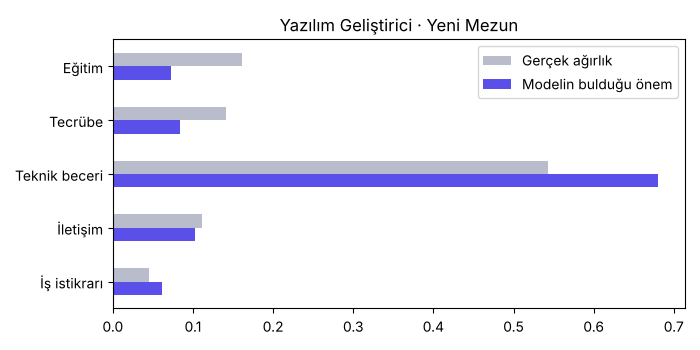

,Gerçek ağırlık,Modelin bulduğu önem
Eğitim,0.161,0.072
Tecrübe,0.141,0.084
Teknik beceri,0.543,0.680
İletişim,0.111,0.102
İş istikrarı,0.045,0.061


In [10]:
compare = pd.DataFrame({
    "Gerçek ağırlık": [weights[f] for f in FEATURES],
    "Modelin bulduğu önem": rf.feature_importances_,
}, index=[LABELS[f] for f in FEATURES]).round(3)

compare.plot.barh(figsize=(7, 3.5), color=["#b9bccb", "#5b4fe9"])
plt.title("Yazılım Geliştirici · Yeni Mezun")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
compare

Çubuklar birbirine yakın: model, teknik becerinin en önemli özellik olduğunu veriden kendisi bulmuş.

## 8. Bütün modellerin sonuçları

`train_candidates.py` 16 modeli eğitip sonuçlarını `models/metrics.json` dosyasına kaydeder. Burada o dosyayı okuyoruz.

In [11]:
with open("models/metrics.json", encoding="utf-8") as f:
    metrics = json.load(f)

rows = []
for p in metrics["positions"].values():
    for lvl, m in p["levels"].items():
        rows.append({
            "Pozisyon": p["name"],
            "Seviye": metrics["levels"][lvl]["name"],
            "RF doğruluk": m["random_forest"]["accuracy"],
            "LR doğruluk": m["logistic_regression"]["accuracy"],
            "F1": m["random_forest"]["f1"],
            "Çapraz doğrulama": m["cross_validation"]["mean"],
        })
pd.DataFrame(rows)

,Pozisyon,Seviye,RF doğruluk,LR doğruluk,F1,Çapraz doğrulama
0,Genel Pozisyon,Stajyer,0.8525,0.8525,0.7774,0.8665
1,Genel Pozisyon,Yeni Mezun (Junior),0.8700,0.8900,0.8015,0.8755
2,Genel Pozisyon,Deneyimli (Orta Seviye),0.8250,0.8550,0.7328,0.8620
3,Genel Pozisyon,Kıdemli (Senior),0.8625,0.8800,0.7970,0.8725
4,Yazılım Geliştirici,Stajyer,0.8925,0.9100,0.8436,0.8880
5,Yazılım Geliştirici,Yeni Mezun (Junior),0.8925,0.9050,0.8413,0.8780
6,Yazılım Geliştirici,Deneyimli (Orta Seviye),0.8725,0.8800,0.8090,0.8715
7,Yazılım Geliştirici,Kıdemli (Senior),0.8950,0.9050,0.8385,0.8795
8,Satış / Müşteri İlişkileri,Stajyer,0.8675,0.8650,0.8114,0.8760
9,Satış / Müşteri İlişkileri,Yeni Mezun (Junior),0.8775,0.8925,0.8165,0.8830


## 9. Adillik (bias) kontrolü

Modele yaş ve cinsiyet verilmiyor. Yine de dolaylı bir haksızlık var mı diye `fairness.py` ile kontrol ettik.
**4/5 kuralı:** en düşük kısa liste oranı, en yüksek oranın en az %80'i olmalı (oran ≥ 0,80).

In [12]:
with open("models/fairness.json", encoding="utf-8") as f:
    fairness = json.load(f)

pd.DataFrame([{
    "Pozisyon": metrics["positions"][pos]["name"],
    "Yaş · tek model": f["age_single"]["ratio"],
    "Yaş · seviyeli sistem": f["age_levels"]["ratio"],
    "Cinsiyet": f["gender"]["ratio"],
} for pos, f in fairness["positions"].items()])

,Pozisyon,Yaş · tek model,Yaş · seviyeli sistem,Cinsiyet
0,Genel Pozisyon,0.1450,0.7483,0.9714
1,Yazılım Geliştirici,0.2175,0.8375,0.9587
2,Satış / Müşteri İlişkileri,0.1889,0.8156,0.9865
3,Proje Yöneticisi,0.0980,0.6943,0.9445


Herkes tek bir modelde yarışırsa tecrübeli (genelde daha yaşlı) adaylar öne geçer ve oran çok düşer.
Adayları kendi seviyesindekilerle karşılaştırınca oran büyük ölçüde düzeliyor. Bu projede seviyeli sistemin kullanılmasının sebebi budur.

## Özet

- Her pozisyon ve seviye için ayrı bir Random Forest modeli eğitildi (16 model).
- Modeller test verisinde yüksek doğruluk veriyor ve çapraz doğrulamada sonuçlar tutarlı.
- Modelin bulduğu önem değerleri gerçek ağırlıklara yakın, yani model doğru kuralı öğreniyor.
- Seviyeli sistem, yaşa dayalı dolaylı ayrımcılığı azaltıyor.